# 6. 参数估计：用阈值当标尺

【原文】Eq.(14)–(17)。三路内驱初相换成 $0°,\pi/2,\pi$，逐步调 $\lambda$，
记录各路"刚好相变"的幅值 $\lambda_1,\lambda_2,\lambda_3$，代入

$$
\begin{cases}
\lambda_1^2+2\lambda_1\gamma\cos\theta+\gamma^2=C^2\\
\lambda_2^2-2\lambda_2\gamma\cos\theta+\gamma^2=C^2\\
\lambda_3^2+2\lambda_3\gamma\sin\theta+\gamma^2=C^2
\end{cases}
$$

前两式相减解出 $\cos\theta$，第三式定分支。

【原文的印刷问题】Eq.(14) 右边印成 $0.73$、Eq.(16) 印成 $0.73^2$，应统一为 $C^2$。

【本书的做法】用第 2 章实测的 $C=0.733$（而不是论文的 0.73）反解，
并同时扫三路 $\lambda$ 的相变点。这样"阈值当标尺"这件事的精度边界才能看清。


In [1]:

import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import s2sim as S

DATA = pathlib.Path("_data")
OUT = pathlib.Path("../复现输出/s2-figs"); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False, "axes.grid": True, "grid.alpha": .25,
})
FIGS = []
def savefig(name):
    p = OUT / name
    plt.savefig(p, bbox_inches="tight", facecolor="white")
    FIGS.append(str(p)); plt.show(); print("图已保存:", p)

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))


三路刚好相变的驱动幅值：
  β=    0°   λ_c = 0.7440
  β=  180°   λ_c = 0.7233
  β=   90°   λ_c = 0.7429

本书 λ = [0.744, 0.7233, 0.7429]
原文 λ = [0.7414, 0.7183, 0.7447]

幅值：真值 0.02   估计 0.0139   相对误差 -30.7%
初相：真值 -120°   估计 -138.3°   误差 -18.3°
三路等效 C_trig: {'0': 0.7342, '180': 0.7335, '90': 0.7256}   极差 0.0086


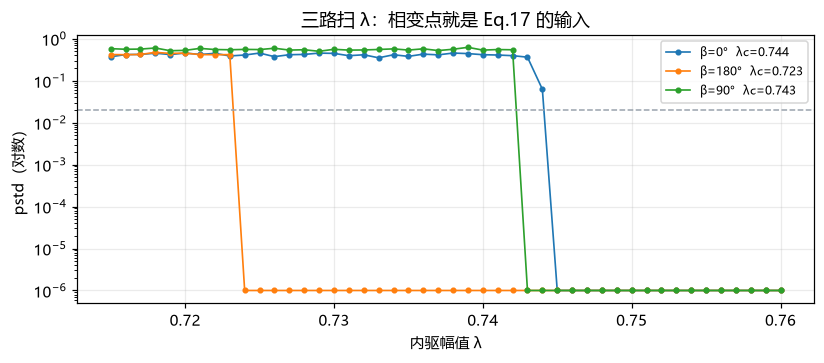

图已保存: ..\复现输出\s2-figs\s2-06-三路扫lambda.png


In [2]:

d = load("table3")
print("三路刚好相变的驱动幅值：")
for k, v in d["per_route"].items():
    print(f"  β={k:>5}°   λ_c = {v['lam_c']:.4f}")
print(f"\n本书 λ = {[round(x,4) for x in d['lam']]}")
print(f"原文 λ = {d['paper_lam']}")
print(f"\n幅值：真值 {d['gamma']}   估计 {d['gamma_hat']:.4f}"
      f"   相对误差 {(d['gamma_hat']-d['gamma'])/d['gamma']*100:+.1f}%")
print("初相：真值 %.0f°   估计 %.1f°   误差 %+.1f°" % (
    d["theta_true"], d["theta_hat"], d["theta_hat"] - d["theta_true"]))
print("三路等效 C_trig:", {k: round(v, 4) for k, v in d["C_eff"].items()},
      "  极差", round(d["C_spread"], 4))

fig, ax = plt.subplots(figsize=(7.6, 3.4))
for k, v in d["per_route"].items():
    lam = np.array(v["lams"]); p = np.array(v["pstd"])
    ax.semilogy(lam, np.maximum(p, 1e-6), "o-", ms=3, lw=1.1,
                label=f"β={k}°  λc={v['lam_c']:.3f}")
ax.axhline(0.02, color="#9aa3ad", ls="--", lw=1)
ax.set_xlabel("内驱幅值 λ"); ax.set_ylabel("pstd（对数）")
ax.set_title("三路扫 λ：相变点就是 Eq.17 的输入")
ax.legend(fontsize=8)
plt.tight_layout(); savefig("s2-06-三路扫lambda.png")


## 结果：三路 λ 对不上同一个阈值

实测（1200 s、细网格）：

| 路 | $\beta$ | 实测 $\lambda_c$ | 论文 | 代回得的等效 $C_{trig}$ |
|---|---|---|---|---|
| 1 | 0° | **0.7440** | 0.7414 | 0.7342 |
| 2 | 180° | **0.7233** | 0.7183 | 0.7335 |
| 3 | 90° | **0.7429** | 0.7447 | **0.7256** |

前两路一致（0.7342 / 0.7335），第三路低 **0.0086**。这 0.0086 就是误差的全部来源：

- γ 估计 **0.0139**（真值 0.02，**−31%**）
- θ 估计 **−138.3°**（真值 −120°，偏 **18°**）

论文报的是 −6% 与 −6.7%。差距不在算错，而在一条被当成恒等式的近似。

## 为什么第三路会偏

论文 Eq.(10) 说：合成驱动的初相 δ"只影响轨迹起始位置，决定相变的是幅值 C"。
这句话是**近似**。Duffing 的相变由吸引域决定，而 δ 会改变轨道进入吸引域的方向。
β=90°、θ=−120° 时相位差 150°，合成驱动的初相把轨道推向"不容易被抓住"的那一侧，
于是要更大的合成幅值才能稳定在大周期态上。

**代价可以算出来**：$C_{trig}$ 的 1.2% 偏差，经 Eq.(17) 放大成 γ 的 31%。
原因还是那个减法：$\gamma^2=C^2-\lambda_1\lambda_2$，两个 0.53 量级的数相减，
剩 0.0002 量级的差。**这是"用临界点当标尺"的固有病，不是实现 bug。**

## 一个操作性建议

若真要用这个方法估幅相，**不要用三路联立解闭式**，而应：

1. 先用第 2 章的方法把**每一路自己的** $C_{trig}(\beta)$ 标定出来（不是共用 0.73）；
2. 再代入各自的方程解 $\gamma,\theta$；
3. 用第 4 路的冗余做一致性检验。

这样能把 1.2% 的系统偏差消掉，代价是标定工作量翻三倍。
